In [2]:
#установка
%pip install kagglehub --quiet

In [3]:
#импорты
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.11.0+cu130


**Загрузка датасета**

In [4]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [5]:
#структура папок
def find_dir(root, name):
    for r, dirs, _ in os.walk(root):
        if name in dirs:
            return os.path.join(r, name)
    raise FileNotFoundError(name)

TRAIN_DIR = find_dir(path, "Training")
TEST_DIR  = find_dir(path, "Testing")
print("Train dir:", TRAIN_DIR)
print("Test dir: ", TEST_DIR)

classes = sorted(d for d in os.listdir(TRAIN_DIR)
                 if os.path.isdir(os.path.join(TRAIN_DIR, d)))
print("Классы:", classes)
for cls in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, cls)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, cls)))
    print(f"  {cls:12s} train: {n_tr:5d} | test: {n_te:4d}")

Train dir: /kaggle/input/brain-tumor-mri-dataset/Training
Test dir:  /kaggle/input/brain-tumor-mri-dataset/Testing
Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']
  glioma       train:  1400 | test:  400
  meningioma   train:  1400 | test:  400
  notumor      train:  1400 | test:  400
  pituitary    train:  1400 | test:  400


**Загрузка изображений в память**

In [6]:
IMG_SIZE = 128

def load_folder(root, per_class=None):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        files = sorted(os.listdir(cls_path))
        if per_class is not None:
            files = files[:per_class]
        for name in files:
            try:
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

t0 = time.time()
X_train_all, y_train_all = load_folder(TRAIN_DIR)
X_test,      y_test      = load_folder(TEST_DIR)
print(f"Train pool: {X_train_all.shape} | Test: {X_test.shape} | {time.time()-t0:.1f}s")

Train pool: (5600, 128, 128, 3) | Test: (1600, 128, 128, 3) | 66.9s


**EDA: примеры и баланс классов**

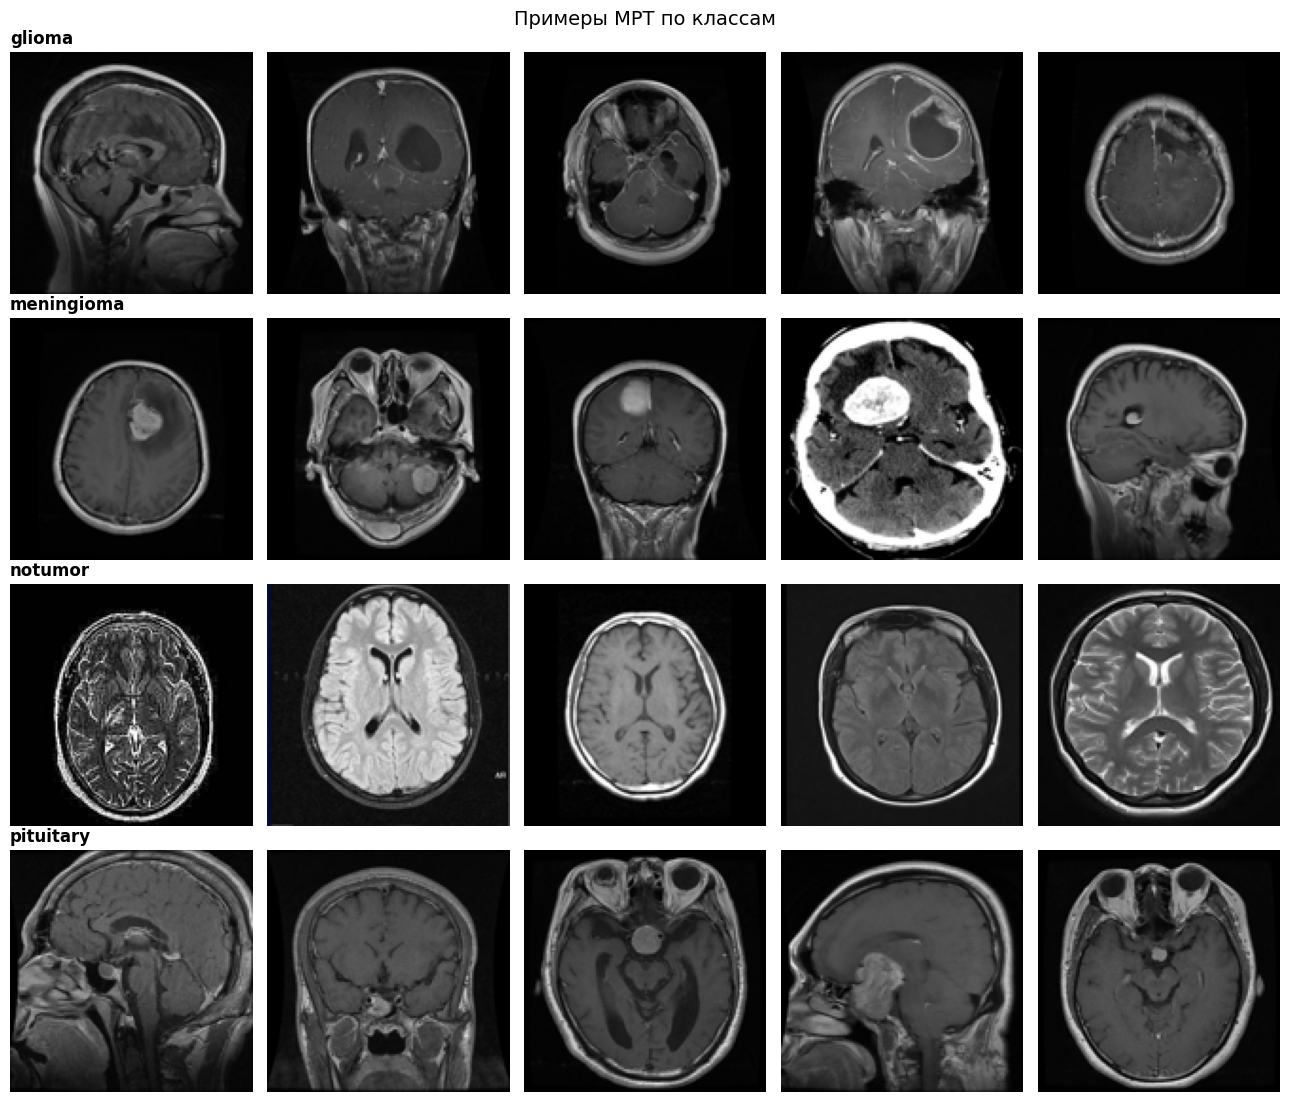

In [7]:
#примеры
fig, axes = plt.subplots(len(classes), 5, figsize=(13, 2.8 * len(classes)))
for row, cls in enumerate(classes):
    idxs = np.random.choice(np.where(y_train_all == cls)[0], 5, replace=False)
    for col, i in enumerate(idxs):
        ax = axes[row, col]
        ax.imshow(X_train_all[i])
        ax.axis("off")
        if col == 0:
            ax.set_title(cls, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Примеры МРТ по классам", fontsize=14)
plt.tight_layout(); plt.show()

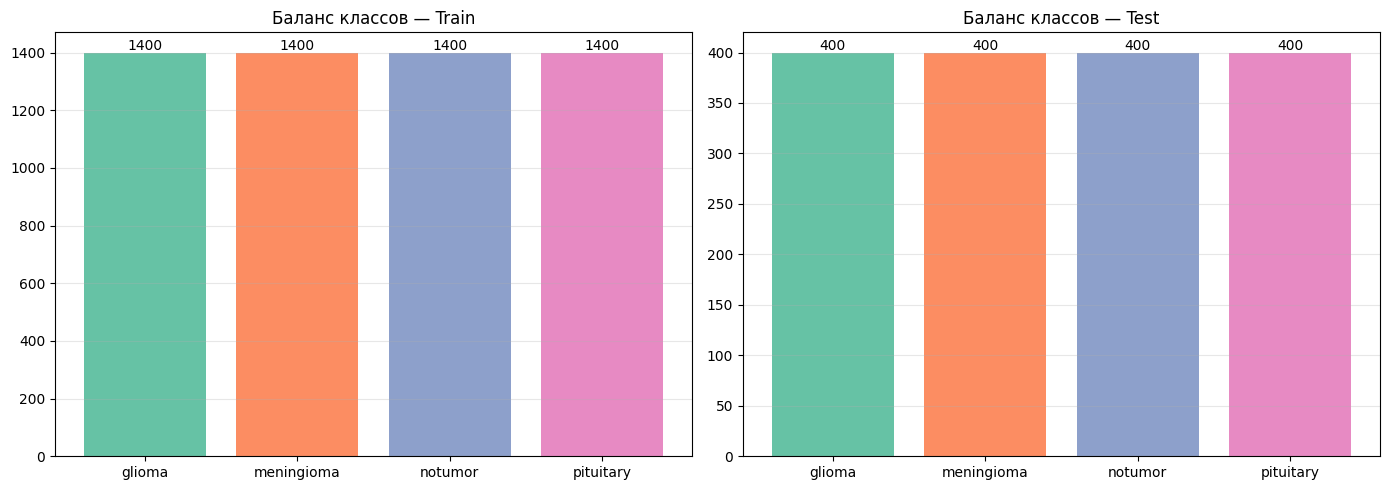

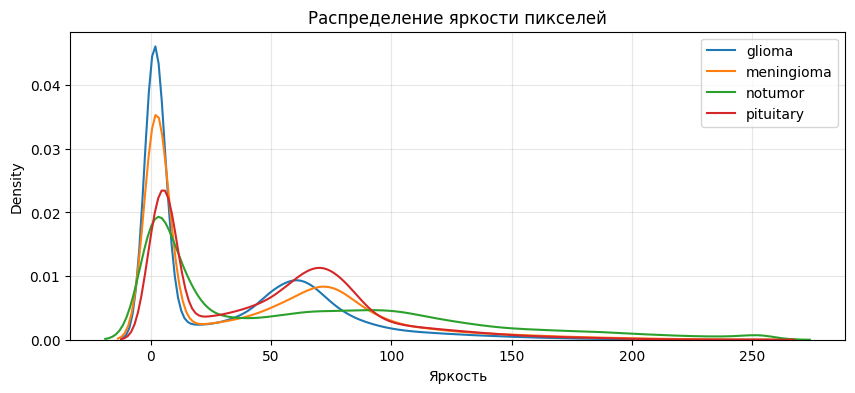

In [8]:
#баланс классов и яркость
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    bars = ax.bar(u, c, color=sns.color_palette("Set2", len(u)))
    ax.bar_label(bars)
    ax.set_title(f"Баланс классов — {ttl}"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

#распределение яркости пикселей по классам
plt.figure(figsize=(10, 4))
for cls in classes:
    sample = X_train_all[y_train_all == cls][:200].mean(axis=3).ravel()
    sns.kdeplot(sample, label=cls, bw_adjust=2)
plt.title("Распределение яркости пикселей"); plt.xlabel("Яркость"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

*Для SimpleCNN нормализуем по статистике train, а для ResNet используем статистику ImageNet (на ней сеть предобучена)*

Train: 4760, Val: 840, Test: 1600
mean: [0.1375 0.1375 0.1375] std: [0.1767 0.1767 0.1767]


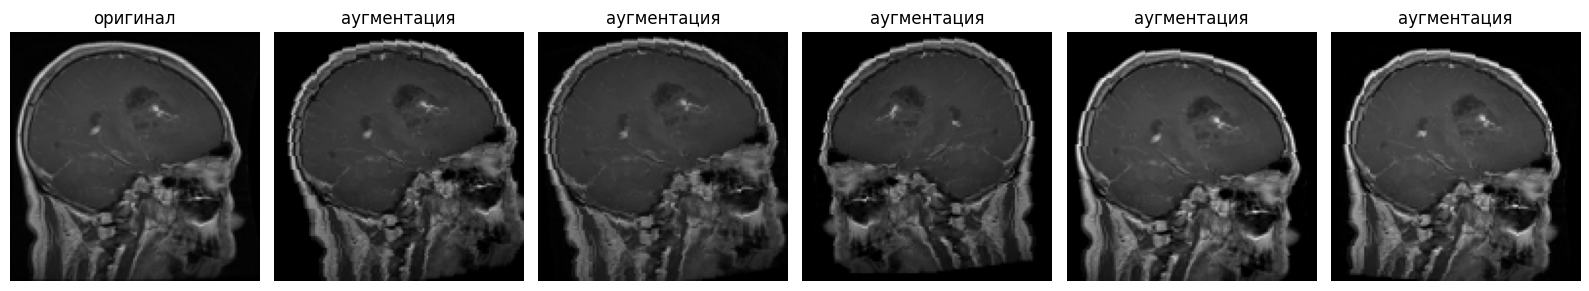

In [9]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
num_classes = len(class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc      = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.15, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

#для своей CNN нормализуем по статистике train
X_train_f = X_train.astype(np.float32) / 255.0
cnn_mean = X_train_f.mean(axis=(0, 1, 2)).tolist()
cnn_std  = X_train_f.std(axis=(0, 1, 2)).tolist()
del X_train_f
print("mean:", np.round(cnn_mean, 4), "std:", np.round(cnn_std, 4))

#для ResNet статистика ImageNet, на которой он предобучен
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

def make_tfms(mean, std):
    train_tfms = T.Compose([
        T.ToPILImage(),
        T.RandomHorizontalFlip(),
        T.RandomRotation(10),
        T.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
        T.ColorJitter(brightness=0.15, contrast=0.15),
        T.ToTensor(),
        T.Normalize(mean=mean, std=std),
    ])
    eval_tfms = T.Compose([
        T.ToPILImage(),
        T.ToTensor(),
        T.Normalize(mean=mean, std=std),
    ])
    return train_tfms, eval_tfms

class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 64
NUM_WORKERS = 2

def make_loaders(train_tfms, eval_tfms):
    train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                              batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS)
    val_loader   = DataLoader(ImageDataset(X_val, y_val, eval_tfms),
                              batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader  = DataLoader(ImageDataset(X_test, y_test_enc, eval_tfms),
                              batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    return train_loader, val_loader, test_loader

cnn_train_tfms, cnn_eval_tfms = make_tfms(cnn_mean, cnn_std)
res_train_tfms, res_eval_tfms = make_tfms(IMAGENET_MEAN, IMAGENET_STD)

cnn_train_loader, cnn_val_loader, cnn_test_loader = make_loaders(cnn_train_tfms, cnn_eval_tfms)
res_train_loader, res_val_loader, res_test_loader = make_loaders(res_train_tfms, res_eval_tfms)

#аугментации
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(X_train[0]); axes[0].set_title("оригинал"); axes[0].axis("off")
for ax in axes[1:]:
    t = cnn_train_tfms(X_train[0])
    t = t * torch.tensor(cnn_std).view(3, 1, 1) + torch.tensor(cnn_mean).view(3, 1, 1)
    ax.imshow(t.permute(1, 2, 0).clamp(0, 1).numpy()); ax.set_title("аугментация"); ax.axis("off")
plt.tight_layout(); plt.show()

**Собственная CNN**

In [10]:
def conv_block(in_ch, out_ch):
    #два свёрточных слоя 3x3 + BatchNorm + ReLU, затем MaxPool(уменьшение в 2 раза)
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2, 2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        #128->64->32->16->8
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1) #256x8x8->256x1x1
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

_model = SimpleCNN(num_classes=num_classes).to(device)
with torch.no_grad():
    print(_model(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape)
print(f"Параметров: {sum(p.numel() for p in _model.parameters()):,}")
del _model

torch.Size([2, 4])
Параметров: 1,206,628


**Функции обучения и оценки**

In [11]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred, y_prob = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
        y_prob.extend(torch.softmax(out, 1).cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred), np.array(y_prob))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": [], "lr": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _, _ = evaluate(model, val_loader, criterion)
        cur_lr = optimizer.param_groups[0]["lr"]
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss", "val_loss", "train_acc", "val_acc", "time", "lr"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt, cur_lr]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {cur_lr:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

**Обучение SimpleCNN**

In [12]:
cnn_model = SimpleCNN(num_classes=num_classes).to(device)
hist_cnn = fit(cnn_model, cnn_train_loader, cnn_val_loader,
               epochs=20, lr=1e-3, weight_decay=1e-4,
               patience=5, title="SimpleCNN")

[SimpleCNN] Ep 01/20 | train loss 0.9096 acc 0.6555 | val loss 0.7962 acc 0.7262 | lr 1.00e-03 | 10.2s
[SimpleCNN] Ep 02/20 | train loss 0.7226 acc 0.7626 | val loss 0.8884 acc 0.6774 | lr 1.00e-03 | 9.6s
[SimpleCNN] Ep 03/20 | train loss 0.6362 acc 0.8082 | val loss 0.7799 acc 0.7083 | lr 1.00e-03 | 9.6s
[SimpleCNN] Ep 04/20 | train loss 0.5860 acc 0.8324 | val loss 0.6196 acc 0.8274 | lr 1.00e-03 | 9.6s
[SimpleCNN] Ep 05/20 | train loss 0.5451 acc 0.8555 | val loss 0.6163 acc 0.8155 | lr 1.00e-03 | 9.7s
[SimpleCNN] Ep 06/20 | train loss 0.5249 acc 0.8592 | val loss 0.6236 acc 0.8119 | lr 1.00e-03 | 9.9s
[SimpleCNN] Ep 07/20 | train loss 0.4869 acc 0.8868 | val loss 0.5025 acc 0.8607 | lr 1.00e-03 | 9.8s
[SimpleCNN] Ep 08/20 | train loss 0.4712 acc 0.8880 | val loss 0.6891 acc 0.7571 | lr 1.00e-03 | 9.9s
[SimpleCNN] Ep 09/20 | train loss 0.4471 acc 0.9011 | val loss 0.4114 acc 0.9167 | lr 1.00e-03 | 10.0s
[SimpleCNN] Ep 10/20 | train loss 0.4349 acc 0.9084 | val loss 0.4456 acc 0.8881

Transfer Learning: ResNet18

Берём ResNet18, предобученную на ImageNet, заменяем последний слой на 4 класса и дообучаем всю сеть с маленьким learning rate

In [13]:
def build_resnet18(num_classes=4, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(model.fc.in_features, num_classes),
    )
    return model

resnet_model = build_resnet18(num_classes=num_classes, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, res_train_loader, res_val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=4, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 190MB/s]


[ResNet18] Ep 01/10 | train loss 0.5360 acc 0.8599 | val loss 0.3368 acc 0.9464 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 02/10 | train loss 0.3549 acc 0.9422 | val loss 0.5161 acc 0.8619 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 03/10 | train loss 0.3159 acc 0.9578 | val loss 0.2752 acc 0.9750 | lr 3.00e-04 | 7.8s
[ResNet18] Ep 04/10 | train loss 0.2860 acc 0.9704 | val loss 0.2782 acc 0.9667 | lr 3.00e-04 | 7.6s
[ResNet18] Ep 05/10 | train loss 0.2696 acc 0.9775 | val loss 0.2510 acc 0.9810 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 06/10 | train loss 0.2555 acc 0.9836 | val loss 0.2390 acc 0.9845 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 07/10 | train loss 0.2407 acc 0.9897 | val loss 0.2407 acc 0.9881 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 08/10 | train loss 0.2480 acc 0.9853 | val loss 0.2591 acc 0.9738 | lr 3.00e-04 | 7.5s
[ResNet18] Ep 09/10 | train loss 0.2459 acc 0.9876 | val loss 0.2771 acc 0.9738 | lr 3.00e-04 | 7.7s
[ResNet18] Ep 10/10 | train loss 0.2339 acc 0.9901 | val loss 0.2304 acc 0.9893 | lr 1.50e-

**Кривые обучения**

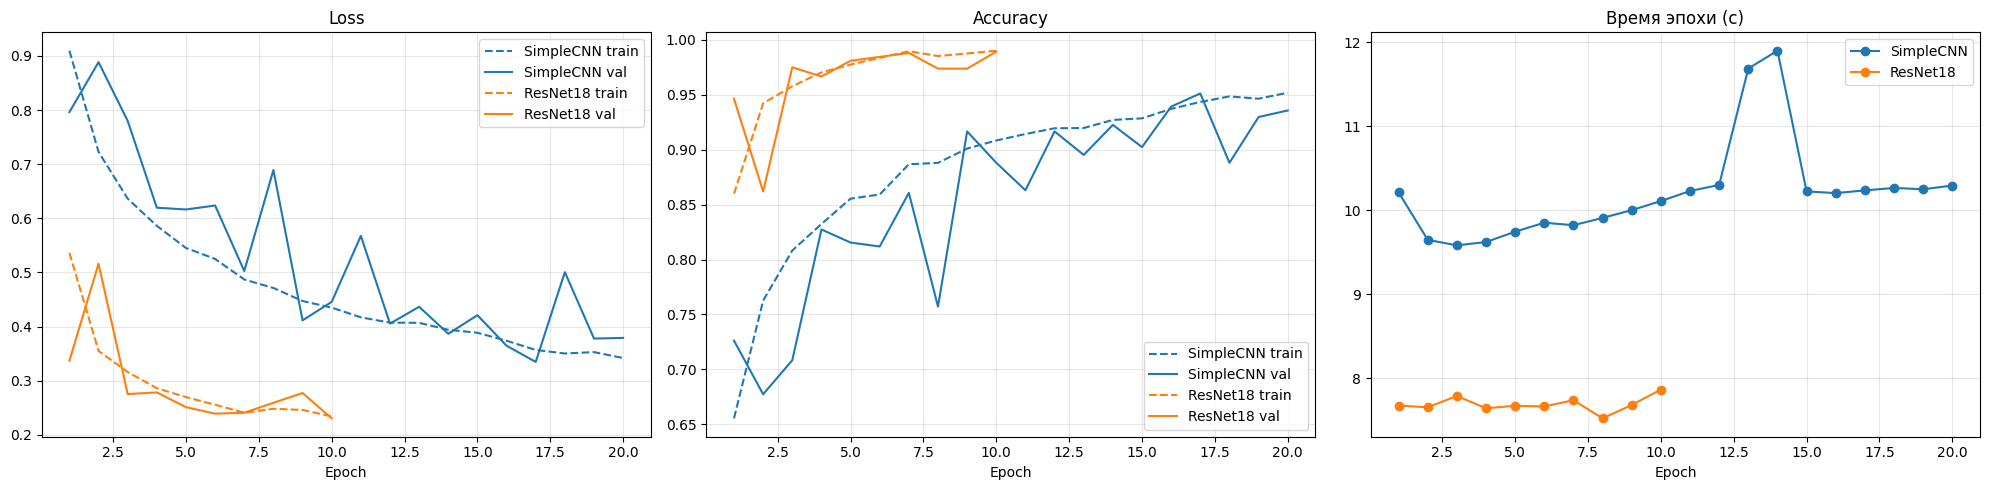

In [14]:
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for (name, h), c in zip(histories.items(), ["tab:blue", "tab:orange"]):
        ep = np.arange(1, len(h["train_loss"]) + 1)
        axes[0].plot(ep, h["train_loss"], "--", color=c, label=f"{name} train")
        axes[0].plot(ep, h["val_loss"],   "-",  color=c, label=f"{name} val")
        axes[1].plot(ep, h["train_acc"],  "--", color=c, label=f"{name} train")
        axes[1].plot(ep, h["val_acc"],    "-",  color=c, label=f"{name} val")
        axes[2].plot(ep, h["time"],       "-o", color=c, label=f"{name}")
    axes[0].set_title("Loss")
    axes[1].set_title("Accuracy")
    axes[2].set_title("Время эпохи (с)")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})

**Оценка на тестовой выборке**


SimpleCNN — Test Accuracy: 0.9256
              precision    recall  f1-score   support

      glioma     0.9816    0.8000    0.8815       400
  meningioma     0.8935    0.9225    0.9077       400
     notumor     0.9126    0.9925    0.9509       400
   pituitary     0.9272    0.9875    0.9564       400

    accuracy                         0.9256      1600
   macro avg     0.9287    0.9256    0.9242      1600
weighted avg     0.9287    0.9256    0.9242      1600


ResNet18 — Test Accuracy: 0.9487
              precision    recall  f1-score   support

      glioma     0.9969    0.8075    0.8923       400
  meningioma     0.8758    0.9875    0.9283       400
     notumor     0.9501    1.0000    0.9744       400
   pituitary     0.9901    1.0000    0.9950       400

    accuracy                         0.9487      1600
   macro avg     0.9532    0.9487    0.9475      1600
weighted avg     0.9532    0.9487    0.9475      1600



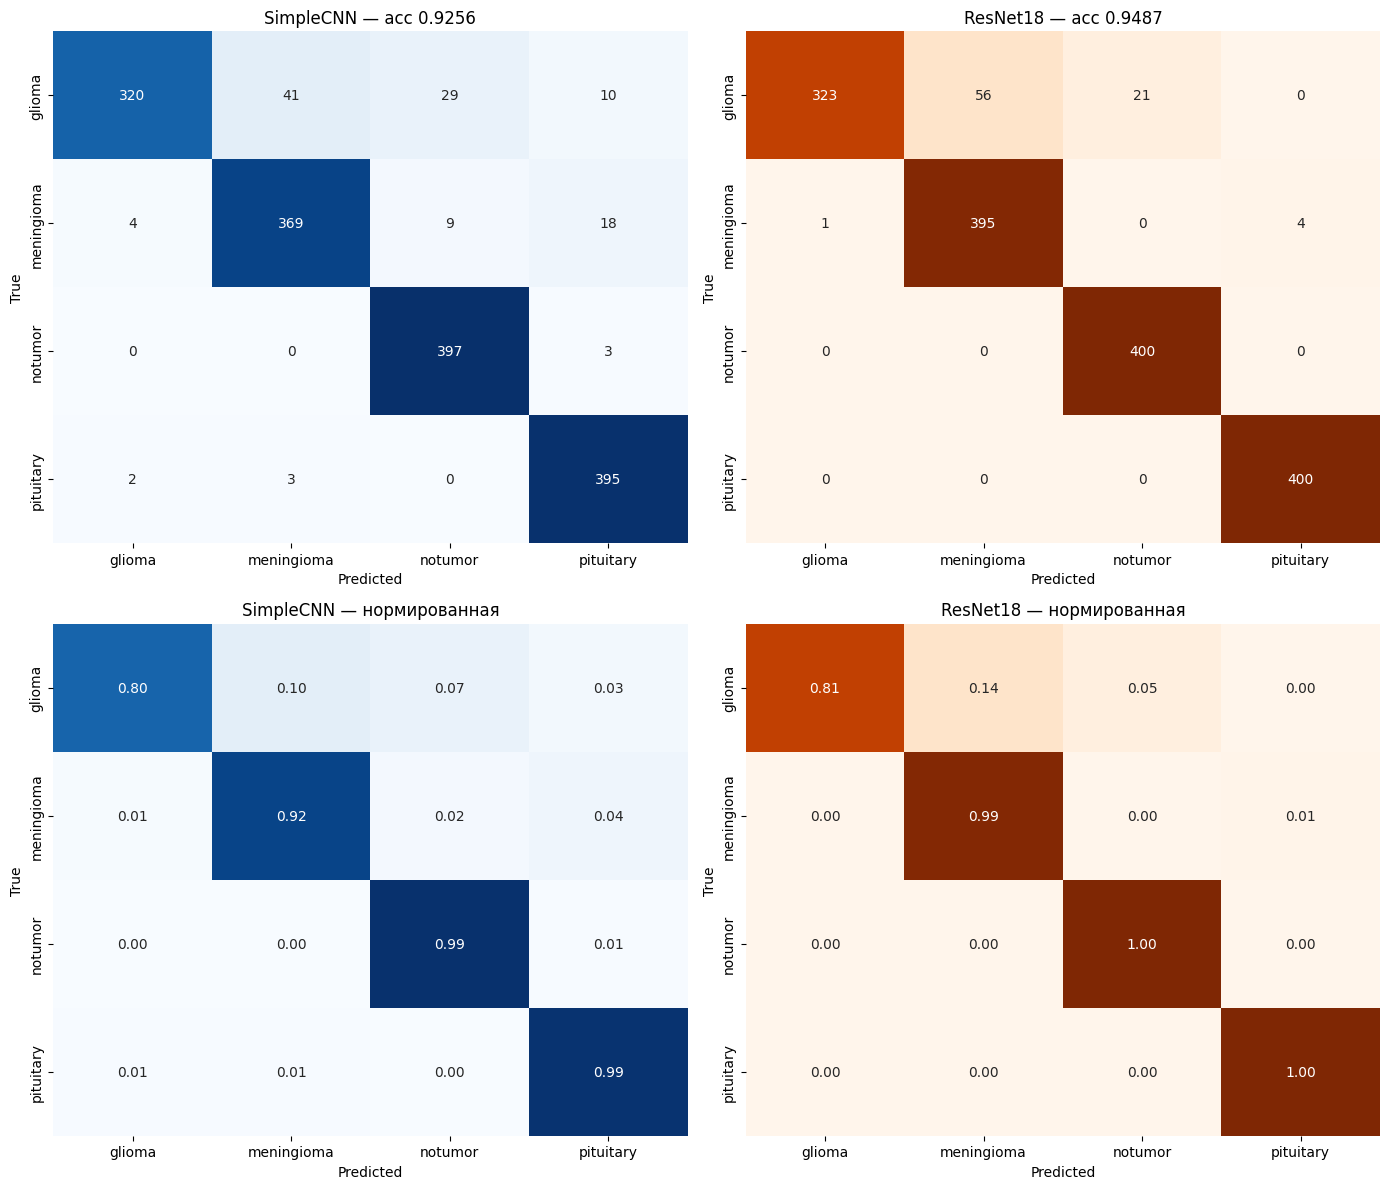

In [16]:
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred, y_prob = evaluate(model, loader, criterion)
    print(f"\n{'='*60}\n{title} — Test Accuracy: {acc:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob}

res_cnn    = full_report(cnn_model,    cnn_test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, res_test_loader, "ResNet18")

#матрицы ошибок рядом: абсолютные и нормированные по строкам(recall)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for col, (name, res, cmap) in enumerate([("SimpleCNN", res_cnn, "Blues"),
                                         ("ResNet18",  res_resnet, "Oranges")]):
    cm = confusion_matrix(res["y_true"], res["y_pred"])
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, ax=axes[0, col],
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap=cmap, ax=axes[1, col], vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names, cbar=False)
    axes[0, col].set_title(f"{name} — acc {res['acc']:.4f}")
    axes[1, col].set_title(f"{name} — нормированная")
    for r in range(2):
        axes[r, col].set_xlabel("Predicted"); axes[r, col].set_ylabel("True")
plt.tight_layout(); plt.show()

**Сравнение моделей**

In [18]:
#таблица
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Params": count_params(model),
        "Best val acc": max(hist["val_acc"]),
        "Test acc": res["acc"],
        "Macro precision": p,
        "Macro recall": r,
        "Macro F1": f,
        "Mean epoch time (s)": np.mean(hist["time"]),
        "Total train time (s)": np.sum(hist["time"]),
        "Epochs trained": len(hist["time"]),
    }

df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn,    res_cnn,    cnn_model),
    summarize("ResNet18",  hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
display(df_cmp.style.format({
    "Params": "{:,}", "Best val acc": "{:.4f}", "Test acc": "{:.4f}",
    "Macro precision": "{:.4f}", "Macro recall": "{:.4f}", "Macro F1": "{:.4f}",
    "Mean epoch time (s)": "{:.1f}", "Total train time (s)": "{:.1f}",
}))

,Params,Best val acc,Test acc,Macro precision,Macro recall,Macro F1,Mean epoch time (s),Total train time (s),Epochs trained
Model,,,,,,,,,
SimpleCNN,"1,206,628",0.9512,0.9256,0.9287,0.9256,0.9242,10.2,204.1,20
ResNet18,"11,178,564",0.9893,0.9487,0.9532,0.9487,0.9475,7.7,76.9,10


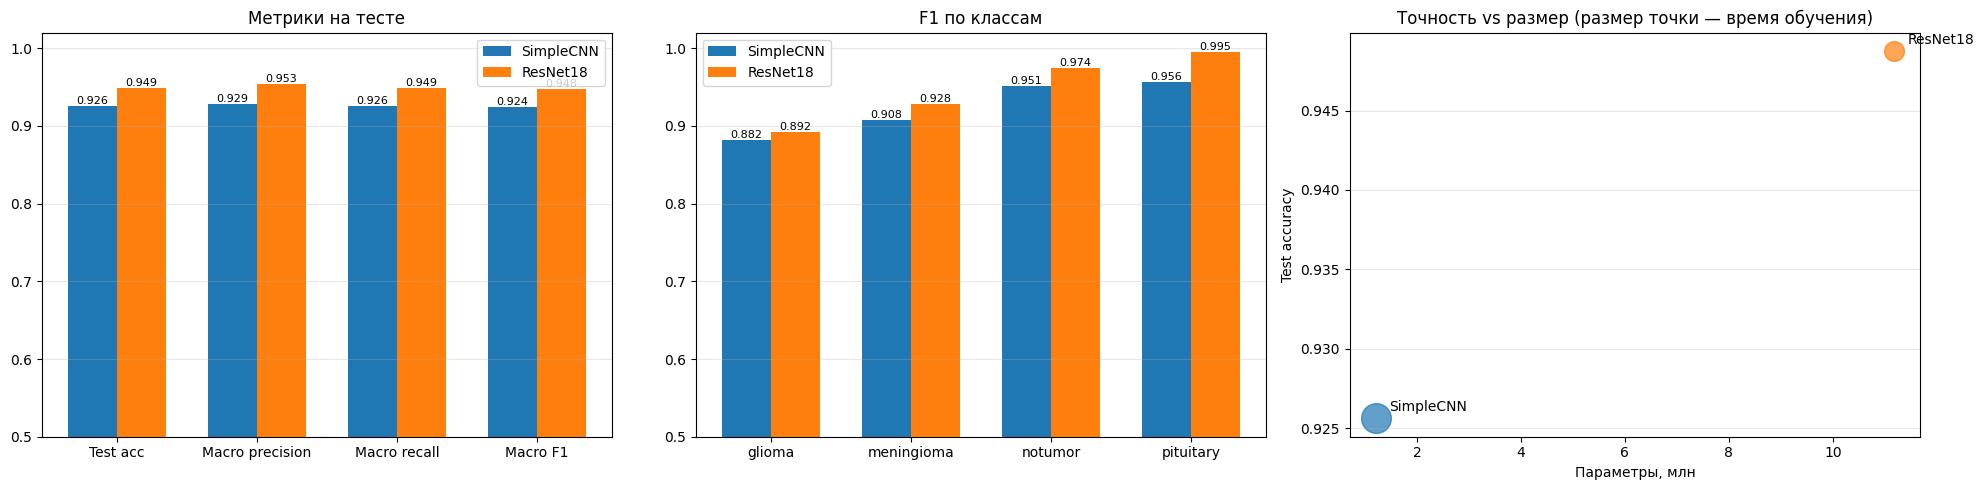

In [19]:
#графики сравнения
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
colors = ["tab:blue", "tab:orange"]

#общие метрики
metrics = ["Test acc", "Macro precision", "Macro recall", "Macro F1"]
x = np.arange(len(metrics)); w = 0.35
for i, name in enumerate(df_cmp.index):
    bars = axes[0].bar(x + (i - 0.5) * w, df_cmp.loc[name, metrics].astype(float),
                       w, label=name, color=colors[i])
    axes[0].bar_label(bars, fmt="%.3f", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(metrics)
axes[0].set_ylim(0.5, 1.02); axes[0].set_title("Метрики на тесте"); axes[0].legend()

#F1 по классам
x = np.arange(num_classes)
for i, (name, res) in enumerate([("SimpleCNN", res_cnn), ("ResNet18", res_resnet)]):
    _, _, f1, _ = precision_recall_fscore_support(res["y_true"], res["y_pred"], zero_division=0)
    bars = axes[1].bar(x + (i - 0.5) * w, f1, w, label=name, color=colors[i])
    axes[1].bar_label(bars, fmt="%.3f", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(class_names)
axes[1].set_ylim(0.5, 1.02); axes[1].set_title("F1 по классам"); axes[1].legend()

#точность vs размер модели
for i, name in enumerate(df_cmp.index):
    axes[2].scatter(df_cmp.loc[name, "Params"] / 1e6, df_cmp.loc[name, "Test acc"],
                    s=df_cmp.loc[name, "Total train time (s)"] * 2 + 50,
                    color=colors[i], label=name, alpha=0.7)
    axes[2].annotate(name, (df_cmp.loc[name, "Params"] / 1e6, df_cmp.loc[name, "Test acc"]),
                     textcoords="offset points", xytext=(10, 5))
axes[2].set_xlabel("Параметры, млн"); axes[2].set_ylabel("Test accuracy")
axes[2].set_title("Точность vs размер (размер точки — время обучения)")
for ax in axes: ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

**Визуализация предсказаний**

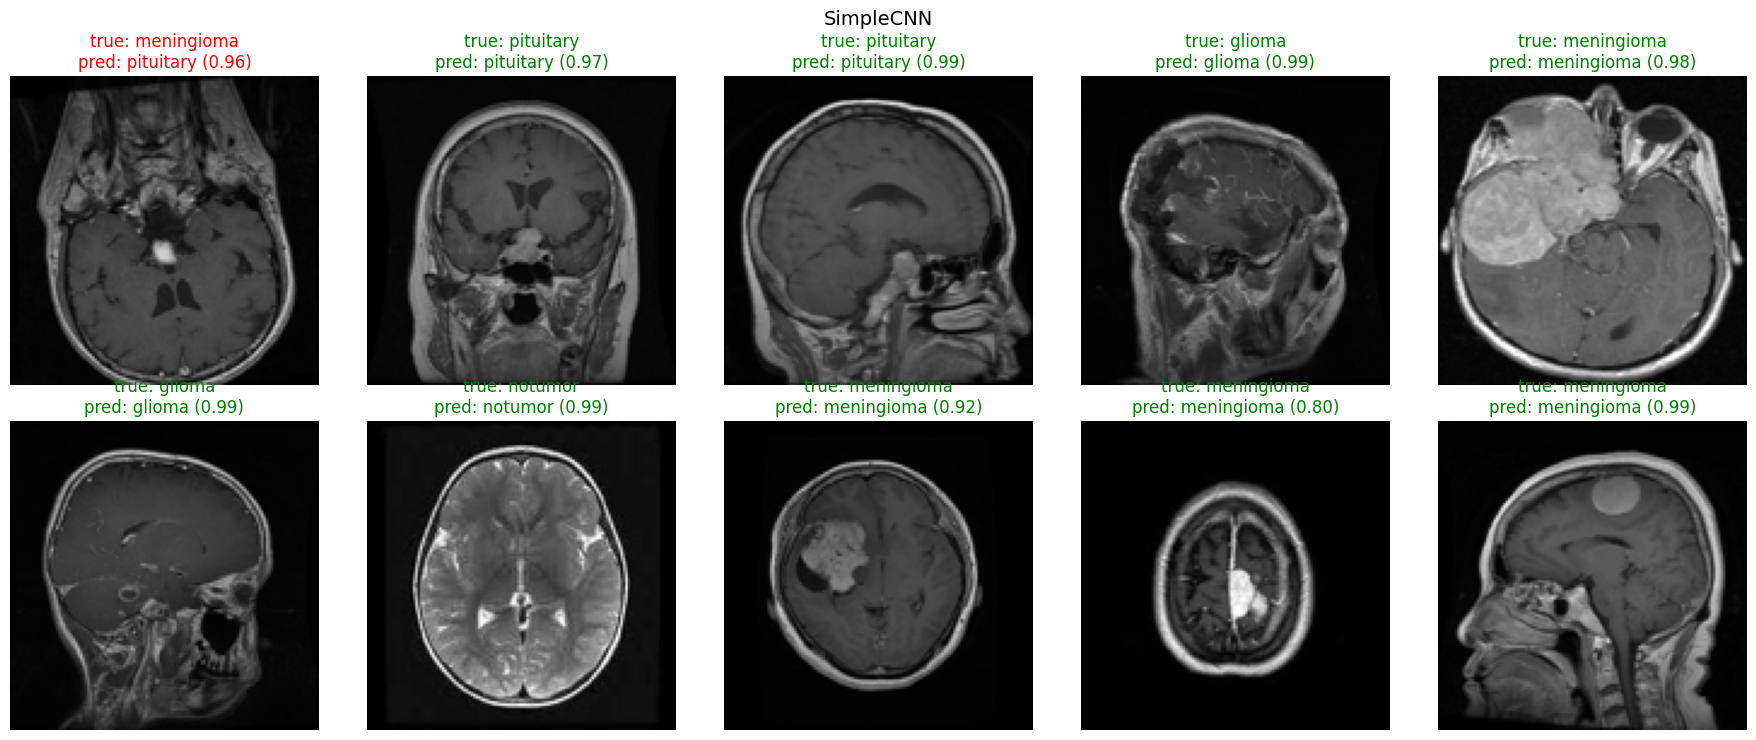

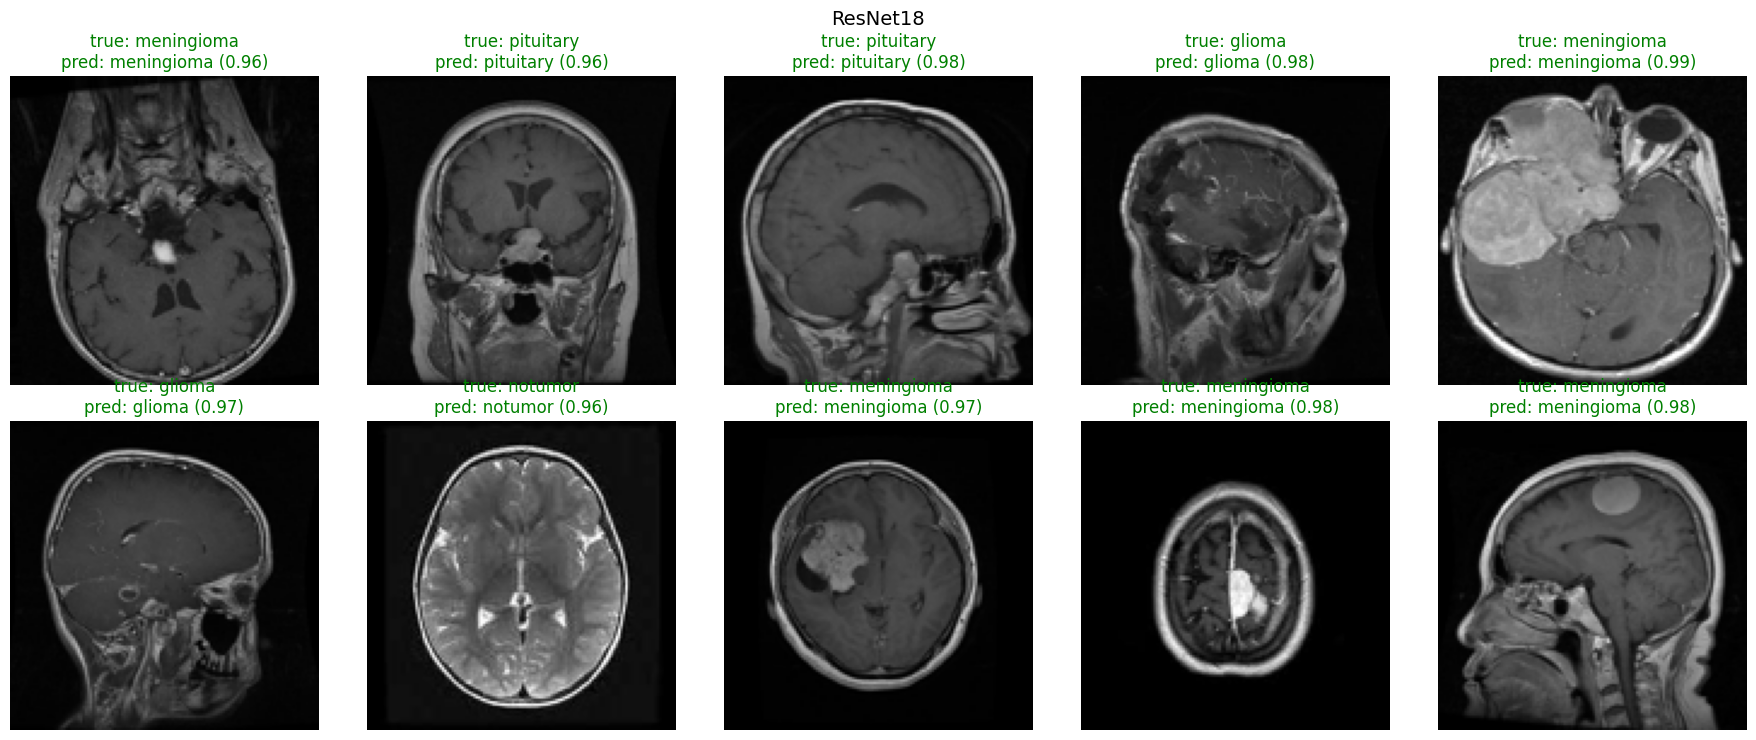

In [21]:
@torch.no_grad()
def show_predictions(model, tfms, images, labels, idxs, title="Model"):
    model.eval()
    fig, axes = plt.subplots(2, len(idxs) // 2, figsize=(18, 7.5))
    for ax, i in zip(axes.ravel(), idxs):
        tensor = tfms(images[i]).unsqueeze(0).to(device)
        prob = torch.softmax(model(tensor), dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))
        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"true: {class_names[labels[i]]}\n"
                     f"pred: {class_names[pred]} ({prob[pred]:.2f})", color=color)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

#одни и те же картинки для обеих моделей
idxs = np.random.choice(len(X_test), 10, replace=False)
show_predictions(cnn_model,    cnn_eval_tfms, X_test, y_test_enc, idxs, title="SimpleCNN")
show_predictions(resnet_model, res_eval_tfms, X_test, y_test_enc, idxs, title="ResNet18")

SimpleCNN: ошибок 119 из 1600


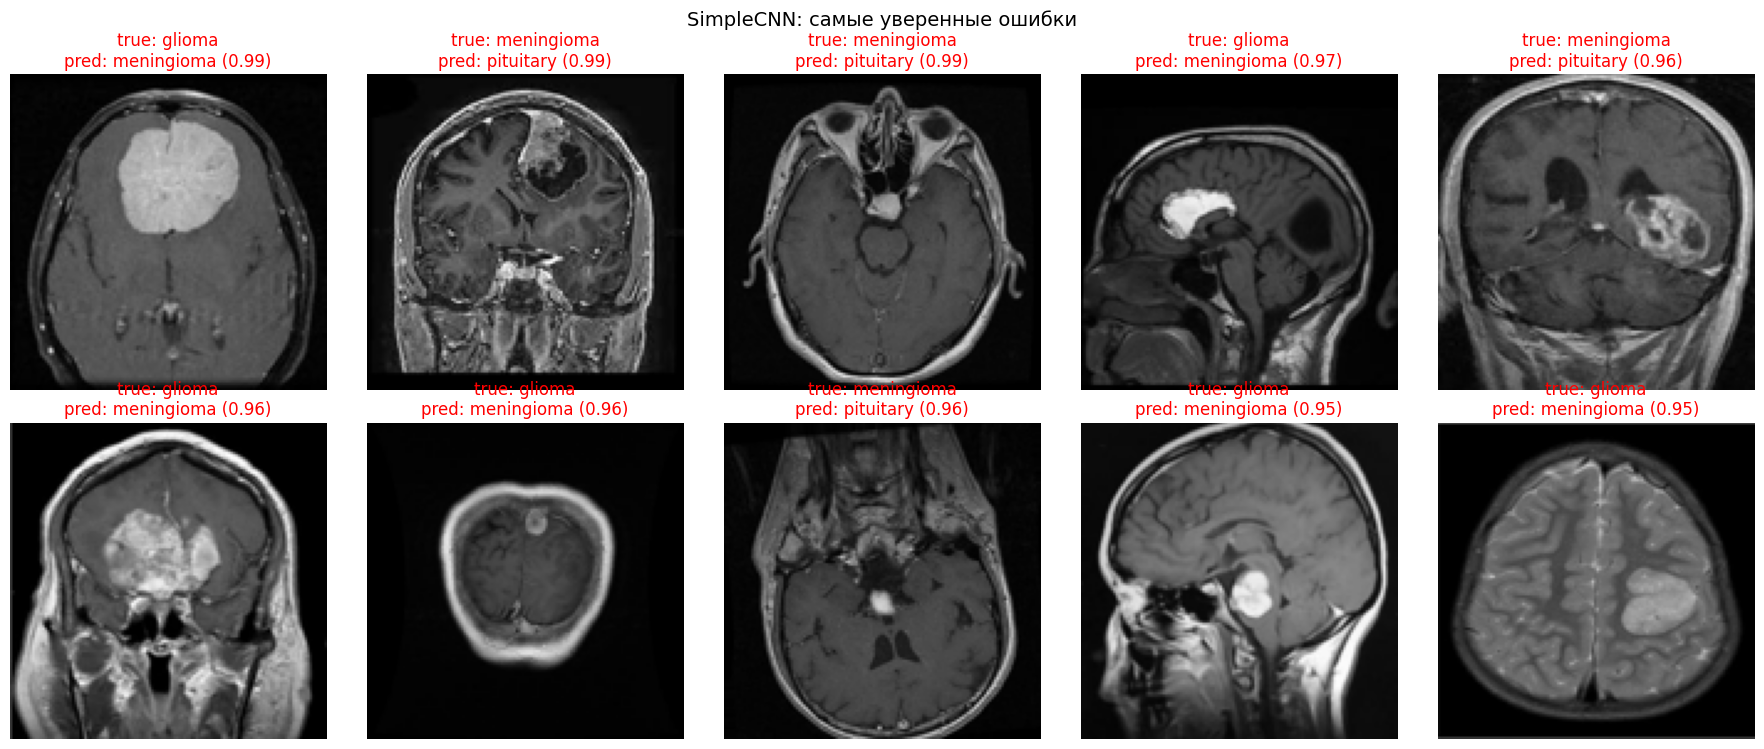

ResNet18: ошибок 82 из 1600


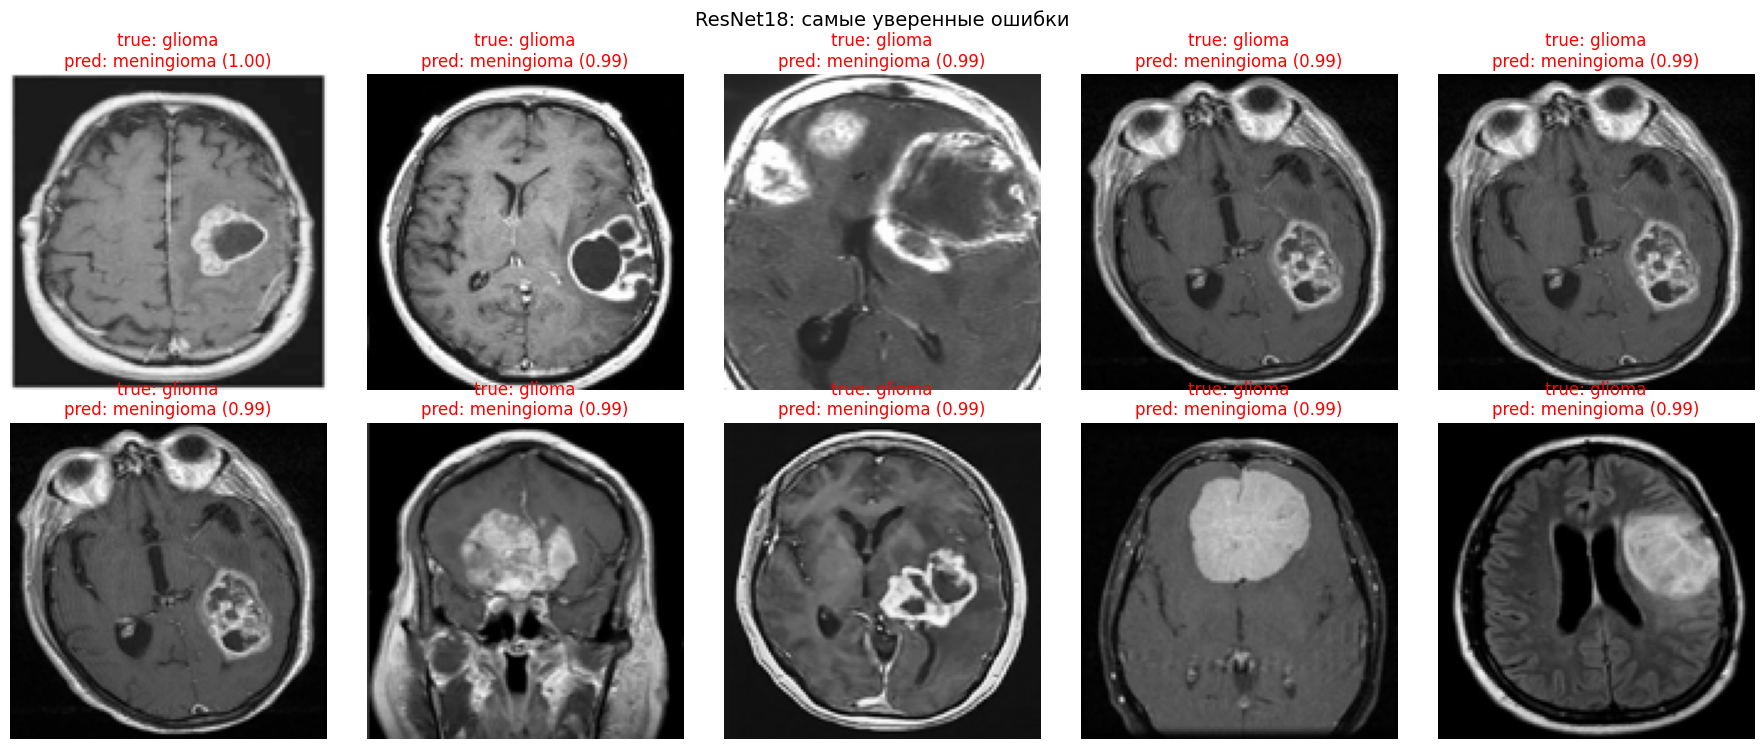

In [22]:
def show_errors(res, title, n=10):
    wrong = np.where(res["y_true"] != res["y_pred"])[0]
    print(f"{title}: ошибок {len(wrong)} из {len(res['y_true'])}")
    if len(wrong) == 0:
        return
    #самые «уверенные» ошибки
    conf = res["y_prob"][wrong, res["y_pred"][wrong]]
    wrong = wrong[np.argsort(-conf)][:n]
    cols = min(5, len(wrong)); rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.8 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(X_test[i])
        ax.set_title(f"true: {class_names[res['y_true'][i]]}\n"
                     f"pred: {class_names[res['y_pred'][i]]} "
                     f"({res['y_prob'][i, res['y_pred'][i]]:.2f})", color="red")
    plt.suptitle(f"{title}: самые уверенные ошибки", fontsize=14)
    plt.tight_layout(); plt.show()

show_errors(res_cnn,    "SimpleCNN")
show_errors(res_resnet, "ResNet18")

Grad-CAM: на какие области смотрят модели

Grad-CAM показывает, какие области изображения сильнее всего повлияли на предсказание. Для МРТ хорошо, если модель смотрит на область опухоли, а не на края снимка или фон.

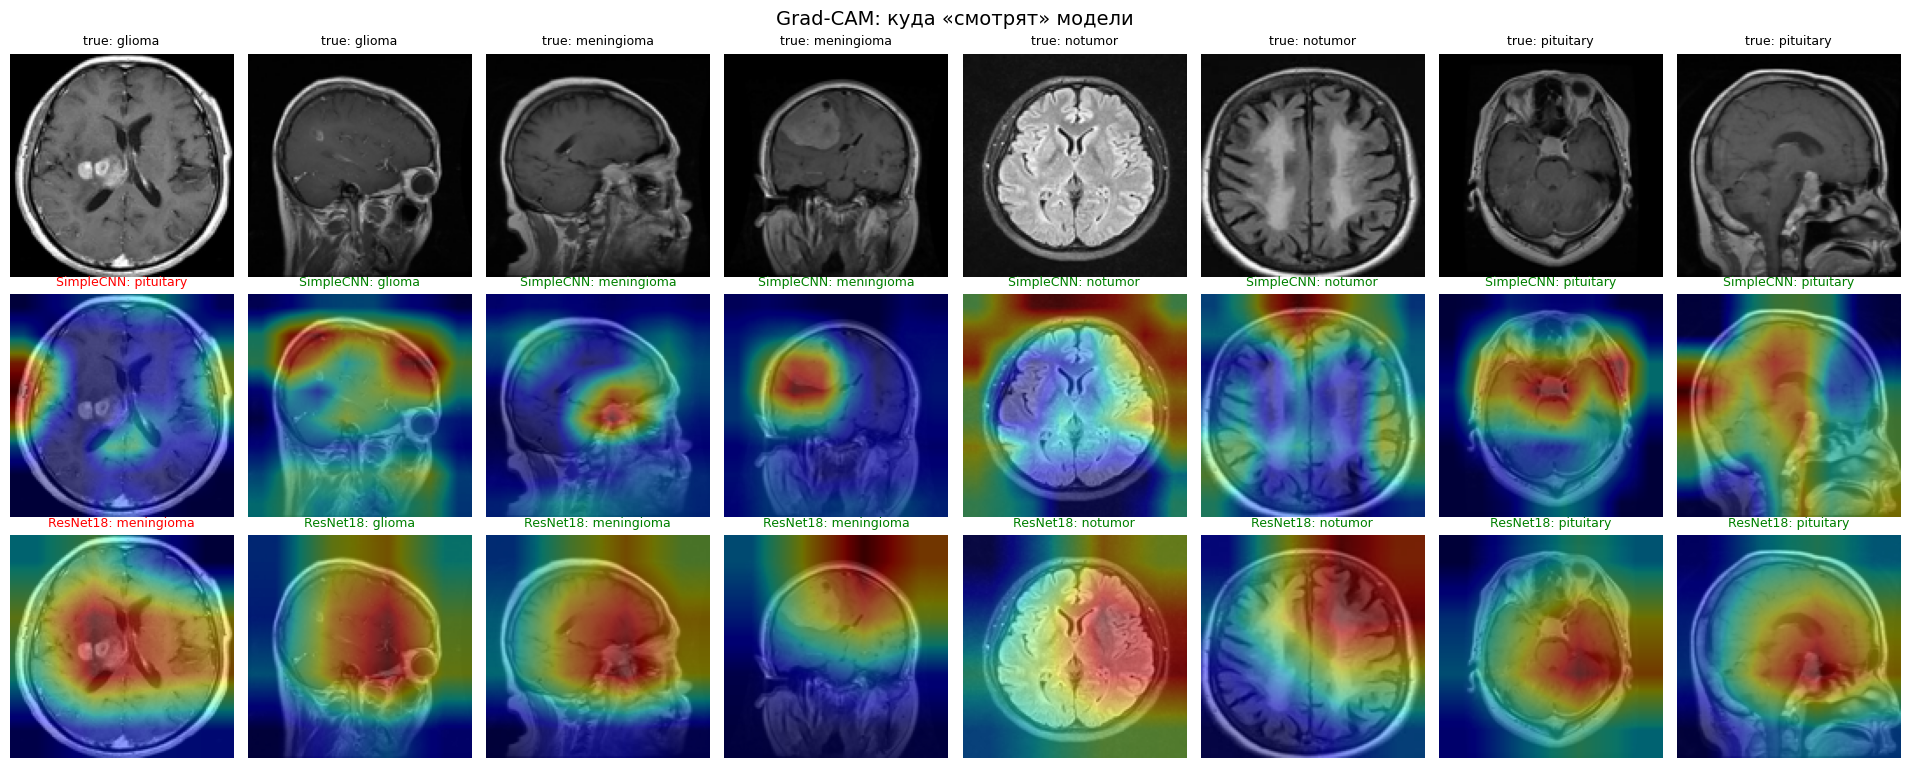

In [23]:
class GradCAM:
    def __init__(self, model, layer):
        self.model = model
        self.acts, self.grads = None, None
        self.handle = layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        self.acts = out
        out.register_hook(lambda g: setattr(self, "grads", g))

    def __call__(self, x):
        self.model.eval()
        with torch.enable_grad():
            out = self.model(x)
            cls = out.argmax(1).item()
            self.model.zero_grad()
            out[0, cls].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, cls

    def remove(self):
        self.handle.remove()

cam_cnn    = GradCAM(cnn_model,    cnn_model.features[-1])
cam_resnet = GradCAM(resnet_model, resnet_model.layer4)

#по 2 картинки каждого класса
cam_idxs = np.concatenate([np.random.choice(np.where(y_test_enc == c)[0], 2, replace=False)
                           for c in range(num_classes)])
fig, axes = plt.subplots(3, len(cam_idxs), figsize=(2.4 * len(cam_idxs), 7.8))
for col, i in enumerate(cam_idxs):
    axes[0, col].imshow(X_test[i])
    axes[0, col].set_title(f"true: {class_names[y_test_enc[i]]}", fontsize=9)
    for row, (name, cam, tfms) in enumerate([("SimpleCNN", cam_cnn, cnn_eval_tfms),
                                              ("ResNet18",  cam_resnet, res_eval_tfms)], start=1):
        heat, pred = cam(tfms(X_test[i]).unsqueeze(0).to(device))
        axes[row, col].imshow(X_test[i])
        axes[row, col].imshow(heat, cmap="jet", alpha=0.45)
        color = "green" if pred == y_test_enc[i] else "red"
        axes[row, col].set_title(f"{name}: {class_names[pred]}", fontsize=9, color=color)
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("Grad-CAM: куда «смотрят» модели", fontsize=14)
plt.tight_layout(); plt.show()

cam_cnn.remove(); cam_resnet.remove()

Итоги

- **SimpleCNN** (~1.2 млн параметров) обучена с нуля: test accuracy = **0.9256**, macro F1 = **0.9242**. За 20 эпох она так и не вышла на плато: val loss ещё снижался, а val accuracy сильно скакала (от 0.76 до 0.95). Значит, ей можно было дать больше эпох.
- **ResNet18** (~11.2 млн параметров, предобучена на ImageNet): test accuracy = **0.9487**, macro F1 = **0.9475**. Уже после первой эпохи val accuracy была 0.946, то есть выше, чем у SimpleCNN после всех 20 эпох. Предобученные признаки хорошо переносятся даже на МРТ, хотя такие снимки сильно отличаются от картинок ImageNet.
- Неожиданно ResNet18 оказалась **быстрее за эпоху** (7.7 с против 10.2 с). Первые слои ResNet сразу уменьшают картинку в 4 раза (stride 2 + MaxPool), а SimpleCNN делает две свёртки на полном разрешении 128×128. В сумме ResNet18 обучалась в 2.6 раза быстрее (77 с против 204 с), хотя параметров у неё в 9 раз больше.
- Самый трудный класс для обеих моделей — **glioma** (recall 0.80 у SimpleCNN и 0.81 у ResNet18). Чаще всего его путают с **meningioma** (41 и 56 снимков) и с **notumor** (29 и 21 снимок). Принять глиому за «нет опухоли» — самая опасная ошибка с медицинской точки зрения.
- Классы **notumor** и **pituitary** ResNet18 распознаёт идеально (recall 1.00), у SimpleCNN recall по ним 0.99. У ResNet18 почти все ошибки уходят в класс meningioma, поэтому его precision ниже (0.876), хотя recall 0.99.
- У ResNet18 большой разрыв между val (0.989) и test (0.949). Валидация взята из папки Training, а тестовая выборка, похоже, немного отличается по распределению. Почти весь разрыв даёт класс glioma.
- **Grad-CAM:** SimpleCNN на части снимков чётко выделяет опухоль (например, менингиому), но на других смотрит на края черепа и на фон над головой. Особенно это заметно для класса notumor и на ошибке glioma → pituitary. У ResNet18 карты грубее (последний слой у неё всего 4×4), поэтому они размытые и покрывают в основном центральную область мозга. Ошибка glioma → meningioma у ResNet18 случилась, хотя модель смотрела прямо на опухоль: она нашла образование, но перепутала его тип.
- **Вывод:** transfer learning даёт лучшее качество (+2.3 п.п. accuracy, на 37 ошибок меньше) за меньшее время обучения. Своя CNN тоже работает неплохо (92.6%) при в 9 раз меньшем числе параметров.
- Что можно улучшить: обучать SimpleCNN дольше (30–40 эпох с CosineAnnealing), поднять разрешение до 224 (у ResNet будут детальнее карты Grad-CAM, и, вероятно, она реже будет путать glioma и meningioma), добавить веса классов или focal loss для glioma, попробовать EfficientNet-B0 и TTA.
